# 🚢 Titanic Survival Prediction
 
## Objective
The goal of this project is to predict whether a passenger survived the Titanic disaster based on features like age, gender, passenger class, and fare.
 
## Dataset
- **Source:** [Kaggle Titanic Competition](https://www.kaggle.com/c/titanic)
- **Size:** 891 rows × 12 columns
- **Target variable:** `Survived` (0 = Did not survive, 1 = Survived)
## Approach
1. Exploratory Data Analysis (EDA)
2. Data Cleaning
3. Feature Engineering
4. Model Training — Logistic Regression vs Random Forest
5. Model Evaluation
 

## 📦 Step 1 — Importing Libraries
---
We begin by importing all the libraries we need for this project.
 
| Library | Purpose |
|---|---|
| `pandas` | Data loading and manipulation |
| `numpy` | Numerical operations |
| `matplotlib` | Base plotting library |
| `seaborn` | Statistical visualisations |
| `scikit-learn` | Machine learning models |
 
---

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 1 — Load the Dataset

In [29]:
df = pd.read_csv('../data/train.csv', index_col = 'PassengerId')
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Step 2 — Understanding the Data
 
Before cleaning or modelling, we need to understand what we are working with — how many rows, what columns exist, what data types they are, and basic statistics.

In [30]:
df.shape
df.info()
df.describe()



<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    str    
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    str    
 10  Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 76.7 KB


,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Step 3 — Data Cleaning
 
### 3a. Missing Values
First, let's identify which columns have missing values and how many.

In [31]:
df.isnull().sum()


Survived      0
Pclass        0
Name          0
Sex           0
Age         177
SibSp         0
Parch         0
Ticket        0
Fare          0
Cabin       687
Embarked      2
dtype: int64

### 3b. Fixing Missing Values
 
**Strategy:**
- `Age` → Fill with **median** (preferred over mean as age can be skewed)
- `Embarked` → Fill with **mode** (most frequent port)
- `Cabin` → **Drop** the column (over 70% values are missing — not useful)

In [32]:
# Fill Age with median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill Embarked with mode
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Drop Cabin column — too many missing values (>70%)
df = df.drop(columns=['Cabin'])
 
# Verify all missing values are handled
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
Parch       0
Ticket      0
Fare        0
Embarked    0
dtype: int64


## Step 4 — Exploratory Data Analysis (EDA)
 
Now we explore the data visually to understand patterns and relationships. We will look at:
- Overall survival count
- Survival by gender
- Survival by passenger class
- Age distribution by survival

### 4a. Overall Survival Count

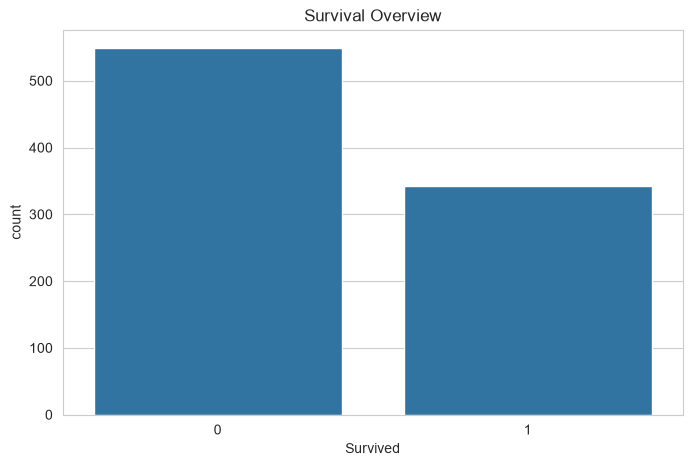

In [33]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Survived')
plt.title("Survival Overview")
plt.show()

> **Insight:** More passengers did not survive than survived. This class imbalance is important — it means our model will naturally be better at predicting deaths than survivals.

### 4b. Survival by Gender

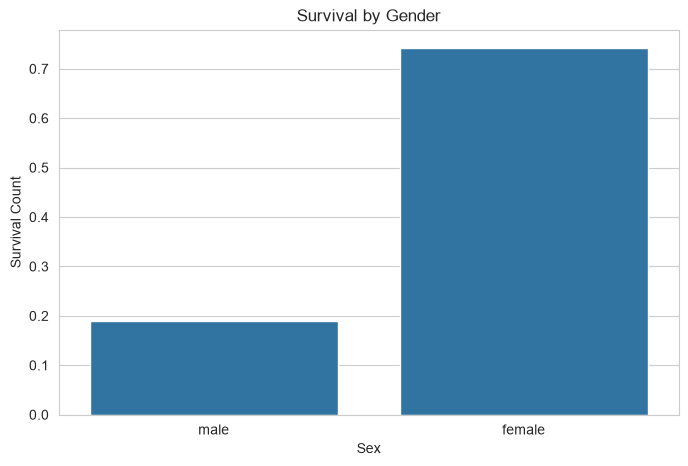

In [34]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x="Sex", y="Survived", errorbar=None)
plt.title("Survival by Gender")
plt.ylabel("Survival Count")
plt.show()

> **Insight:** Women had a significantly higher survival rate than men, confirming the "women and children first" evacuation protocol followed on the Titanic.

### 4c. Survival by Passenger Class

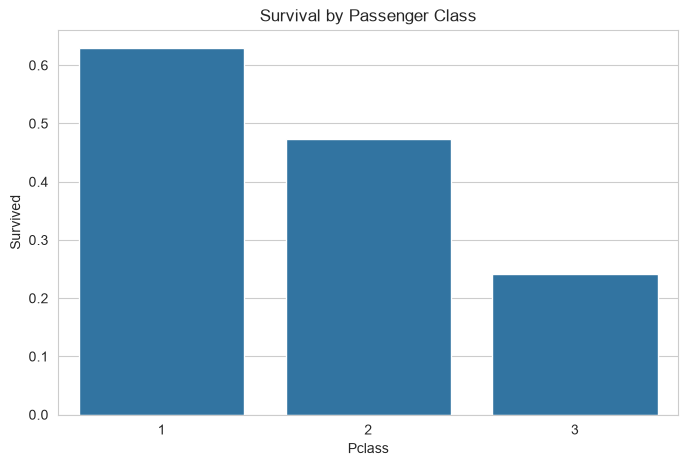

In [35]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x="Pclass", y="Survived", errorbar=None)
plt.title("Survival by Passenger Class")
plt.show()

> **Insight:** First class passengers had the highest survival rate, followed by second class. Third class passengers had the lowest survival rate — likely because they were located deeper in the ship and had less access to lifeboats.
 
### 4d. Age Distribution by Survival

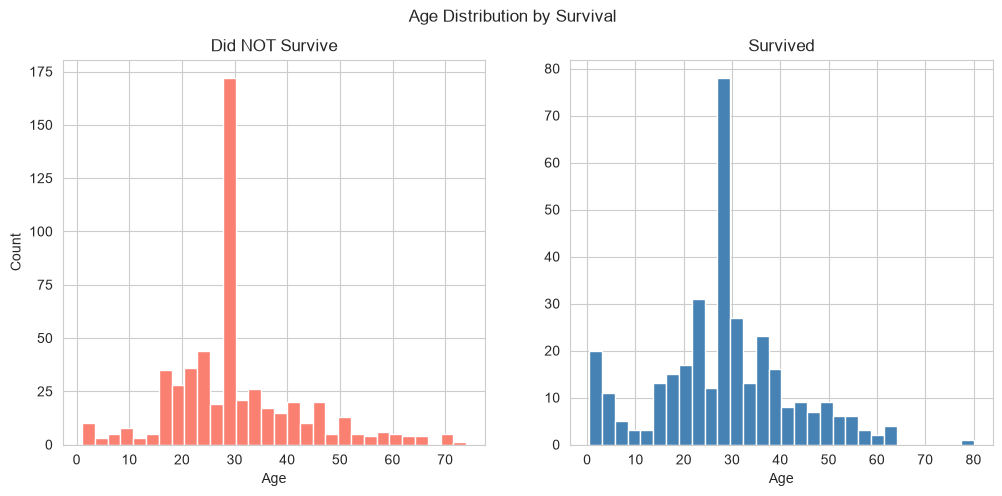

In [36]:
# Age distribution split by survival status
# Two separate charts to avoid overlap confusion
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
 
# Passengers who did not survive
axes[0].hist(df[df['Survived']==0]['Age'], bins=30, color='salmon')
axes[0].set_title('Did NOT Survive')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')
 
# Passengers who survived
axes[1].hist(df[df['Survived']==1]['Age'], bins=30, color='steelblue')
axes[1].set_title('Survived')
axes[1].set_xlabel('Age')
 
plt.suptitle('Age Distribution by Survival')
plt.show()

> **Insight:** Age alone is not a strong predictor of survival. The distribution shape is similar for both groups. However, children under 10 had a slightly better survival chance, consistent with the evacuation protocol. The Y-axis difference (175 vs 80) further confirms that more people died than survived overall.

## Step 5 — Feature Preparation
 
Before training our model, we need to:
1. Convert categorical columns to numbers (ML models only understand numbers)
2. Select the most relevant features
3. Separate features (X) from the target variable (y)

In [37]:
# Convert Sex to binary — male: 1, female: 0
df['Sex'] = df['Sex'].map({'male': 1, 'female': 0})
 
# Select features most likely to predict survival
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']]
 
# Target variable — what we want to predict
y = df['Survived']
 
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature preview:")
print(X.head())

Features shape: (891, 6)
Target shape: (891,)

Feature preview:
             Pclass  Sex   Age  SibSp  Parch     Fare
PassengerId                                          
1                 3    1  22.0      1      0   7.2500
2                 1    0  38.0      1      0  71.2833
3                 3    0  26.0      0      0   7.9250
4                 1    0  35.0      1      0  53.1000
5                 3    1  35.0      0      0   8.0500


## Step 6 — Train Test Split
 
We split our data into:
- **80% training set** → the model learns from this
- **20% test set** → we evaluate the model on unseen data
`random_state=42` ensures we get the same split every time we run the code.

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(len(X))
print(len(X_train))
print(len(X_test))


891
712
179


## Step 7 — Model Training and Evaluation
 
We train two models and compare their performance:
1. **Logistic Regression** — simple, interpretable, good baseline
2. **Random Forest** — ensemble of decision trees, generally more powerful


In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
lr_acc = accuracy_score(y_test, lr_pred)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)

# Print accuracies
print("Logistic Regression Accuracy:", round(lr_acc * 100, 2), "%")
print("Random Forest Accuracy:", round(rf_acc * 100, 2), "%")

# Print classification reports
print("\n--- Logistic Regression Report ---")
print(classification_report(y_test, lr_pred))

print("\n--- Random Forest Report ---")
print(classification_report(y_test, rf_pred))


Logistic Regression Accuracy: 81.01 %
Random Forest Accuracy: 79.89 %

--- Logistic Regression Report ---
              precision    recall  f1-score   support

           0       0.81      0.88      0.84       105
           1       0.80      0.72      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179


--- Random Forest Report ---
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       105
           1       0.77      0.73      0.75        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



c:\Users\Prapsss\Titanic-Survival-Prediction\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Step 8 — Confusion Matrix
 
A confusion matrix shows us exactly where our model is making mistakes:
- **True Negatives (top left)** → correctly predicted did not survive
- **False Positives (top right)** → wrongly predicted survived
- **False Negatives (bottom left)** → wrongly predicted did not survive
- **True Positives (bottom right)** → correctly predicted survived

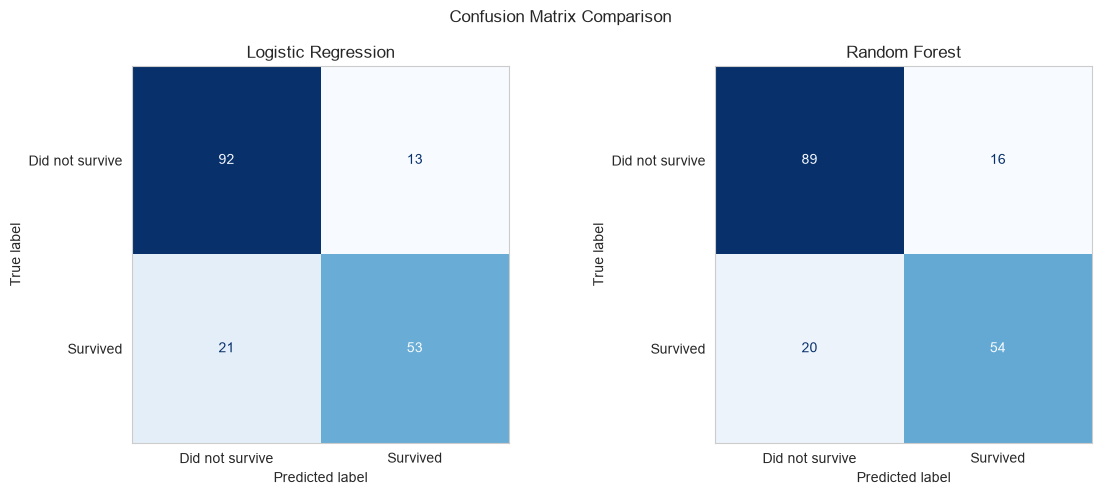

In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_lr = confusion_matrix(y_test, lr_pred)
cm_rf = confusion_matrix(y_test, rf_pred)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression confusion matrix
ConfusionMatrixDisplay(cm_lr, display_labels=['Did not survive', 'Survived']).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Logistic Regression')
axes[0].grid(False)

# Random Forest confusion matrix
ConfusionMatrixDisplay(cm_rf, display_labels=['Did not survive', 'Survived']).plot(ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title('Random Forest')
axes[1].grid(False)

plt.suptitle('Confusion Matrix Comparison')
plt.tight_layout()
plt.show()




## Conclusion
 
| Model | Accuracy |
|---|---|
| Logistic Regression | 81.01% |
| Random Forest | 79.89% |
 
**Key findings from this project:**
- **Gender** was the strongest predictor of survival — women survived at a much higher rate
- **Passenger class** was the second strongest predictor — first class had the best survival rate
- **Age** alone was not a strong predictor, though children under 10 had slightly better survival chances
- Interestingly, the simpler **Logistic Regression outperformed Random Forest** — a reminder that complex models are not always better
**What I learned:**
- End-to-end ML workflow — from raw data to trained model
- Handling missing values with median and mode imputation
- Visualising data with seaborn and matplotlib
- Evaluating models using accuracy, classification report, and confusion matrix